<h1>Introduction to Statistics with Python</h1>

Welcome to an introduction to statistics with Python. The goal of this project is to explore the fundamentals of both statistics and Python for data analysis.

From descriptive statistics; measures of central tendency, spread and position, to inferential statistics; sampling and sampling distributions. Python packages; data structures, common functions, methods and visualisations.

<h2>What is Statistics?</h2>

<b>Statistics is the study of the collection, analysis and interpretation of data.</b>

It is about quantifying uncertainty to ultimately help businesses make better decisions, solve complex problems and improve the performance of a service or product.

<h2>What is Python?</h2>

Python is a powerful, high-level, multi-purpose programming language. It's open-sourced code, active community, easy to learn and wide range of libraries has made it <b>the preferred tool for data professionals.</b>

There are many different environments available to use python, one of the most common is here on <b>Jupyter Notebook</b>. An open-sourced web application, this is a great tool for developing and presenting code, right here in a browser.

<h3>Libraries</h3>

Libraries are a vital part of using python for data analysis. These are collections of code that vastly expand the functionality of Python. Let's start with importing a few important libraries that we will need.

In [1]:
# loading packages

# Import NumPy
import numpy as np

# Import Pandas
import pandas as pd

# Import scipy stats
from scipy import stats

<b>Numpy</b> is numerical python. Known for high performance, computational power it allows us to process lange, complex quantities of data. It powers many other libraries, and is an intregal part of advanced data analytics. Numpy contains many useful functions and methods for basic statistics.

<b>Pandas</b> is the most widely used data analysis library packed with tools to work with data in tabular format. It is built on top of NumPy! The key the pandas DataFrame. This is the core tabuler structure data that allows us to do all sorts of analysis. Think of it like a spreadsheet or sql table that can contain a range of different data types. We will frequently use pandas to create and manipulate data in tabular form.

<b>SciPy.Stats</b> is a stats module specifically designed for statistics. Again it is directly built on top of NumPy and is widely used as a one-stop-shop of advanced statistical techniques. As we get into inferential statistics and beyond scipy stats contains a vast arrage of powerful calculations.

In [ ]:
# Import matplotlib
import matplotlib.pyplot as plt

# Import seaborn
%pip install seaborn
import seaborn as sns

In [ ]:
Talk about visualisation libraries

<h3>Reusable plotting function</h3>

In [181]:
# Create reusable plot function for consistent graph styles

# Define styled plot function
def styled_plot(
    # Accept data to be used
    data,
    # Plot type
    plot_type,
    # Specify x and y
    x=None,
    y=None,
    # Title and subtitle
    title="",
    subtitle="",
    # Axis labels
    xlabel=None,
    ylabel=None,
    # Color
    color="#4C72B0",
    # Custom lines
    show_mean=None,
    mean_label="",
    mean_color="4C72B0",
    secondary_mean=None,
    secmean_label="",
    secmean_color="red",
    # Default fig size
    fig_size=(8, 5.5),
    # Allow subplots
    ax=None
):

    # If just one plot, use the fig-size as the entire fig size
    if ax is None:
        fig, ax = plt.subplots(
            figsize=fig_size,
            facecolor="white"
        )

    # Else plot each individual subplot
    else:
        fig = ax.figure

    # Custom settings for different plot types
    if plot_type == "hist":
        sns.histplot(
            data=data,
            bins=30,
            color=color,
            edgecolor="white",
            linewidth=1.5,
            alpha=0.85,
            ax=ax
        )

    elif plot_type == "box":
        sns.boxplot(
            data=data,
            width=0.2,
            linewidth=1.5,
            color=color,
            ax=ax
    )

        sns.despine(
            bottom=True
    )

    elif plot_type == "line":
        sns.lineplot(
            data=data,
            x=x,
            y=y,
            color=color,
            ax=ax
    )

    # Error
    else:
        raise ValueError(
            f"Unsupported plot type: {plot_type}. Update styled_plot function"
        )

    # Clean up axes by removing top and right
    sns.despine(
        top=True,
        right=True
    )

    # Set colour to lighter grey
    ax.spines["left"].set_color("#cbd5e1")
    ax.spines["bottom"].set_color("#cbd5e1")

    # Mean reference line plotting
    if show_mean:
        ax.axvline(
            data.mean(),
            linestyle="--",
            color=mean_color,
            linewidth=1.5,
            label=mean_label
        )

     # Secondary reference line
    if secondary_mean:
        ax.axvline(
            secondary_mean,
            linestyle="--",
            color=secmean_color,
            linewidth=1.5,
            label=secmean_label
        )

    # Frame to plot
    if show_mean or secondary_mean is not None:
        ax.legend(frameon=False)

    # Axis formatting
    ax.tick_params(
        axis="both",
        colors="#64748b",
        labelsize=11,
        length=0,
        pad=8
    )

    # X label formatting
    ax.set_xlabel(
        xlabel,
        color="#475569",
        fontsize=12,
        labelpad=12
    )

    # Y label formatting
    ax.set_ylabel(
        ylabel,
        color="#475569",
        fontsize=12,
        labelpad=12
    )

    # Title
    ax.text(
        0.0, 1.14,
        title,
        transform=ax.transAxes,
        fontsize=18,
        fontweight="bold",
        color="#1e293b",
        ha="left"
    )

    # Subtitle
    ax.text(
        0.0, 1.07,
        subtitle,
        transform=ax.transAxes,
        fontsize=12,
        color="#64748b",
        ha="left"
    )

    return fig, ax

<h1>Descriptive Statistics</h1>

Descriptive statistics describe or summarise the main features of a dataset. They are useful for quickly understanding large amount of data.

Let's create a numpy array and dataframe versions of our data that we can use in this demonstration:

In [3]:
# Create a numpy array
data = np.array([1, 2, 4, 4, 5, 8, 9, 10])

# Create a dataframe from this array
df = pd.DataFrame({'Value': data})

<h2>Measures of Central Tendency</h2>

Measures of central tendency are values that represent the centre of a dataset. Helping us quickly understand its overall structure.

<h3>Mean</h3>

The mean is the average value of a dataset, calculated by the sum of all values divded by the number of values. So lets do just that!

In [4]:
# Calculate the sum of values
sum = np.sum(df)
print("Sum:", sum)

# Calculate the number, or length, of values
count = len(df)
print("Count:", count)

# Divide sum of values by the count of values
print("Mean:", sum / count)

Sum: 43
Count: 8
Mean: 5.375


Rather than doing this every time we want the mean, instead we can use NumPy's built in .mean() method:

In [5]:
# Calculate mean using numpy
mean = np.mean(df)

print("Mean:", mean)

Mean: 5.375


The mean is an extremely important fundamental to statistics as we will explore. But it is particularly <b>useful as a measure of centre when their are no outliers in a dataset</b>.

<h3>Median</h3>

Median is the middle value in a dataset. Half the values are smaller and half are larger than the median, wen there is an odd number of values, it is half way between the middle two values.

In [6]:
# Calculate median
median = np.median(df)

print(df.to_string(index=False))
print("Median:", median)

 Value
     1
     2
     4
     4
     5
     8
     9
    10
Median: 4.5


In this case, the median is between 4 and 5, as we have an even number of values in our dataset. The median is most useful when there are significant outliers in a dataset, the ends can be extreme but the median will look to the middle values regardless.

<h3>Mode</h3>
    
Mode is the most frequently occuring value in a dataset. A dataset could have no, one or more than one mode. In this case we can use SciPy stats:

In [7]:
# Calculate mode
mode = stats.mode(df).mode

# Print a frequency table and mode
print(pd.DataFrame(np.unique(df, return_counts=True)).T.to_string(index=False))
print("Mode:", mode)

 0  1
 1  1
 2  1
 4  2
 5  1
 8  1
 9  1
10  1
Mode: [4]


We can see here with a frequency table that '4' appears twice in this dataset and is therefore the mode. The mode is <b>most useful to find a measure of central tendency with categorical data</b>

<h2>Measures of Spread</h2>

Measures of spread describe the variation in a dataset. Looking out from the centre of our data, let's are exploring how the data is dispered outwards.

Doing just that, lets first look at how far each data point is away from the mean by creating a new version of our dataframe:

In [8]:
# Distance from mean

# Create a new instance of our dataframe to use
sd_df = df.copy()

# Create a new column by takking the value minus the mean
sd_df['Distance from mean'] = sd_df['Value'] - mean

# Display this new table
print("Mean::", mean)
print(sd_df.to_string(index=False))

Mean:: 5.375
 Value  Distance from mean
     1              -4.375
     2              -3.375
     4              -1.375
     4              -1.375
     5              -0.375
     8               2.625
     9               3.625
    10               4.625


So here we add a column for how 'far away' each point is from the mean by minusing the mean from each point. Now the trouble is by trying to average this distance of the mean, the negative numbers will simply cancel out the positive ones:

In [9]:
# Attempting to average distances from mean
print(sd_df['Distance from mean'].mean())

0.0


What we can do is square each number so that they are all positive:

In [10]:
# Add a squared distance column
sd_df['Squared distance'] = sd_df['Distance from mean'] ** 2

# Display table now with three columns
print(sd_df.to_string(index=False))

 Value  Distance from mean  Squared distance
     1              -4.375         19.140625
     2              -3.375         11.390625
     4              -1.375          1.890625
     4              -1.375          1.890625
     5              -0.375          0.140625
     8               2.625          6.890625
     9               3.625         13.140625
    10               4.625         21.390625


We now have the distance from the mean all in positive values, allowing us to calculate variance.

<h3>Variance</h3>

Variance is the average of the squared differences of each data point from the mean. Let's perform this calculation just as we did the mean of the original values in the dataset:

In [11]:
# Manual calculation of variance

# Calculate sum of the squared distance
ssqd = sd_df['Squared distance'].sum()

# Calculate count of squared distance
csqd = sd_df['Squared distance'].count()

# Print variance calculation
print("Sum of squared distance:", ssqd)
print("Count of values:", csqd)
print("Variance:", round(ssqd / csqd, 2))

Sum of squared distance: 75.875
Count of values: 8
Variance: 9.48


In the same way before, we can do this much quicker with NumPy!

In [12]:
# Calculate variance using numpy
var = round(np.var(data), 2)

print("Variance:", var)

Variance: 9.48


Variance is a crucial way to quantify how spread out our data is, but it cannot be directly compared to our original values.

<h3>Standard Deviation</h3>

Standard deviation measures the typical distance each datapoint is from the mean. It is the square root of variance, as we return it after being squared to the original unit of measurement:

In [13]:
# Manual calculation of standard deviation from variance
sd = np.sqrt(var)

print("Standard deviation:", round(sd, 2))

Standard deviation: 3.08


As always, we can do this all in one line with numpy:

In [14]:
# Calculate standard deviation with NumPy
sd = round(np.std(df['Value']), 2)

print("Standard deviation:", sd)

Standard deviation: 3.08


So we have ended up at a value we can use to quantify each distance from the mean.

<h4>Why can't we use absolute values instead of squaring?</h4>

This is something I wondered for a while, the standard deviation isn't actually the mean difference right? No, turns out you can! This value is called the <b>Mean Absolute Deviation</b>. Instead of squaring and square rooting, we simply take the absolute value:

In [15]:
# Mean deviation

# Create a new instance of our dataframe to use
md_df = df.copy()

# Create a new column by taking the value minus the mean
md_df['Distance from mean'] = (df['Value'] - mean)
md_df['Absolute distance'] = md_df['Distance from mean'].abs()

# Calculate mean deviation
mean_deviation = md_df['Absolute distance'].mean()

# Display this new table
print(md_df.to_string(index=False))
print("Mean absolute deviation::", round(mean_deviation, 2))

 Value  Distance from mean  Absolute distance
     1              -4.375              4.375
     2              -3.375              3.375
     4              -1.375              1.375
     4              -1.375              1.375
     5              -0.375              0.375
     8               2.625              2.625
     9               3.625              3.625
    10               4.625              4.625
Mean absolute deviation:: 2.72


In the exact same way as our measures of central tendency, we can also use the median.

In [16]:
# Calculate median deviation
median_deviation = md_df['Absolute distance'].median()

# Display this new table
print("Median absolute deviation::", median_deviation)

Median absolute deviation:: 3.0


Despite this being a more intuitive understanding of spread, <b>standard deviation is preferred</b> as it results in smoother mathematical properties with more advanced calculations.

<h3>Range</h3>

Finally range is simply the difference between the largest and smallest number of a dataset, useful for quickly understanding the distance from the extreme ends.

In [17]:
# Calculate the max value
max = np.max(df)
print("Max:", max)

# Calculate the min value
min = np.min(df)
print("Min:", min)

# Minus min from the max value
print("Range:", max - min)

Max: 10
Min: 1
Range: 9


For this dataset our max value is 10, while the min is 1, resulting in a range of 9. Two datasets could have the same mean, but have very different ranges.

<h2>Measures of Position</h2>

Measures of position determine the relative position of the values in a dataset. It is about putting data points in context with how they are related to one another.

<h3>Percentiles</h3>

Percentiles are the values below which a percentage of the data falls. For instance, we can look at the 90th percentile:

In [18]:
# Calculate 90th percentile
p90 = np.percentile(df, 90)

print("90th percentile:", p90)

90th percentile: 9.3


At 9.3, 90% of our data falls below this number, and 10% above. Percentile are useful for comparing values quickly, to gain a general understanding of a dataset.

<h3>Quartiles</h3>

Quartiles are the percentiles that divide a dataset into four equal parts; 25, 50, and 75 percent.

In [19]:
# Calculate quartiles
q1, q2, q3 = np.percentile(df, [25, 50, 75])

print("Q1:", q1)
print("Q2:", q2)
print("Q3:", q3)

Q1: 3.5
Q2: 4.5
Q3: 8.25


The 50th percentile is the same as our median, the middle of the dataset, splitting it in two. The 25th and 75th are then the median of those two halves, creating quarters.

<h3>Interquartile range</h3>

The interquartile range is the distance from the first and third quartile, the middle 50% of the data.

In [20]:
# Calculate interquartile range
iqr = q3 - q1

print("IQR:", iqr)

IQR: 4.75


Here are iqr is 4.75, 50% of our data falls between 3.5 and 8.25. The IQR can be helpful to remove outliers and quickly understand the range in which the middle of our data falls.

<h3>Describe (5 number summary)</h3>

These combine to make the five number summary; the minimum, first quartile, median, third quartile and maximum.

As has been a theme so far, numpy almost always has a quicker method for calculating

In [21]:
df.describe()

,Value
count,8.000000
mean,5.375000
std,3.292307
min,1.000000
25%,3.500000
50%,4.500000
75%,8.250000
max,10.000000


Together they provide an overview of the distribution of data and are commonly visualised with a box plot.

(<Figure size 800x550 with 1 Axes>, <Axes: >)

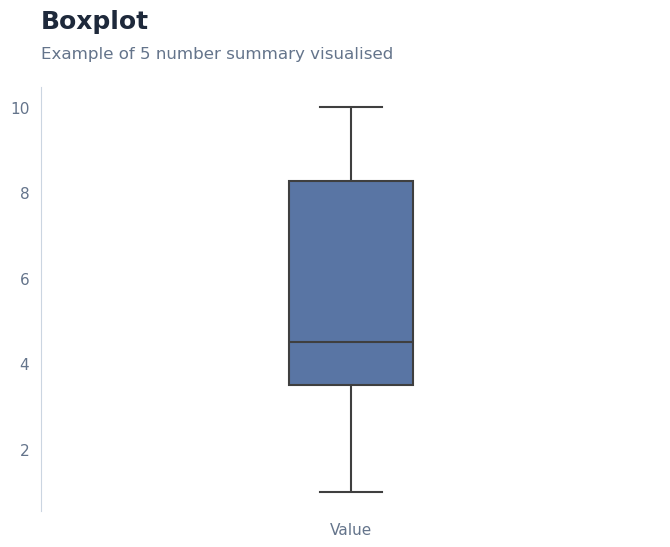

In [168]:
# Used custom styled_plot function
styled_plot(
    plot_type="box",
    data=df,
    title="Boxplot",
    subtitle="Example of 5 number summary visualised"
)

plt.show()

<h1>Inferential Statistics</h1>

Often it simply takes too many resources, or is impossible to collect every single data point needed to perform descriptive statistics. So what can we do? Can we learn about the whole if we only have a part?

Inferential statistics uses a subset of data (**sample**) to draw conclusions or make predictions about the whole group (**population**). 

Based on a small sample of available data, inferential statistics can be used to make informed **estimations about unknown values of a population**.

<h3>Population</h3>

To explore inferential statistics, let's start by creating a dataset of 1000 random numbers from 0 to 100. This will be our **population**; all of the data points we are interested in for the purpose of this activity.

In [25]:
# Create population dataset

# Instantiate numpy random number generator
# 42 is a seed number, we can reuse to get the same numbers again
rng = np.random.default_rng(42)

# Create a dataset of 1000 random numbers between 0 and 100
population = rng.integers(
    low=0, 
    high=100, 
    size=1000, 
    endpoint=True
)

# Calculate length
population_size = len(population)

# Print population length and previous
print("Population size:", population_size)
print("Population first 10 numbers:", population[:10])

Population size: 1000
Population first 10 numbers: [ 9 78 66 44 43 86  8 70 20  9]


Let's apply what we learned in descriptive statistics by calculating the **mean** and **standard deviation** of this population:

In [26]:
# Descriptive summary of the population

# Calculate mean and standard deviation
population_mean = population.mean()
population_sd = np.std(population, ddof=0)

# Display the population mean and standard deviation
print("Population mean:", round(population_mean, 2))
print("Population standard deviation:", round(population_sd, 2))

Population mean: 50.31
Population standard deviation: 29.13


Our population has a mean of 50.3 and a standard deviation of 29.1. In inferential statistics we refer to these as **population parameters**.

A population parameter is a numerical characteristic that describes the population. For this purpose of this demonstration we have the advantge of knowing these population parameters. In the real world, a population parameter is an **unknown value** that we would be trying to estimate.

Let's visualise what our population looks like with a histogram plot to understand its shape:

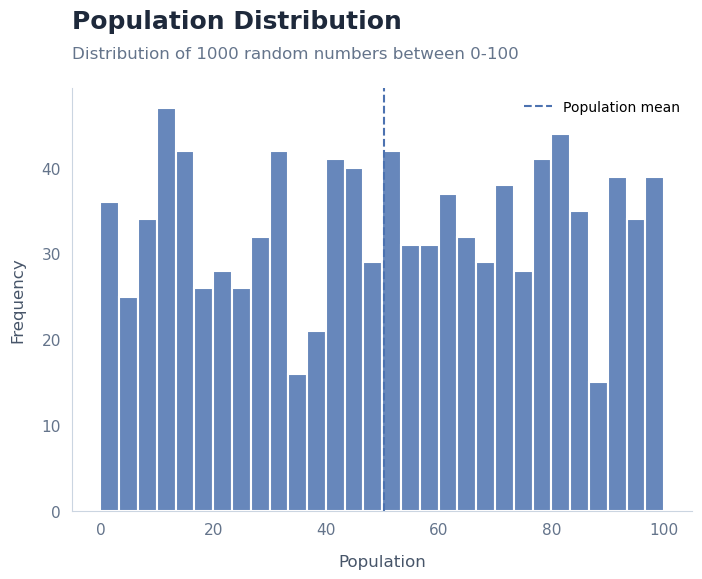

In [182]:
# Used custom styled_plot function

styled_plot(
    plot_type="hist",
    data=population,
    title="Population Distribution",
    subtitle="Distribution of 1000 random numbers between 0-100",
    xlabel="Population",
    ylabel="Frequency",
    color="#4C72B0",
    show_mean=True,
    mean_label="Population mean",
    mean_color="#4C72B0"
)

plt.show()

<h2>Sampling</h2>

Let's pretend now that we are only able to see a **small portion of this population data**.

Sampling is the process of selecting a subset of data from a population. Samples require **significantly less resources** than measuring the entire population, which can often be logistically impossible.

For a sample to be accurate, it needs to reflect the wider population. Sampling processes help to ensure we have a representative sample. For this oversimplified example, we can select numbers from random. This is called **simple random sampling**.

Let's try sampling 10 random numbers from our population:

In [125]:
# Generate simple random sample sample

# Instantiate numpy random number generator
# 42 is a seed we can reuse to get the same numbers again
rng = np.random.default_rng(42)

# Generate a sample of 10 data points from the population
sample = rng.choice(population, size=10, replace=False)

# Show sample data
print(sample)

[70 48 77 85 57  8 25 90 91 85]


Here are our 10 randomly numbers. Let's calculate the mean and standard deviation of this sample as we did for our population:

In [127]:
# Calculate sample statistics

# Instantiate numpy random number generator
# 42 is a seed we can reuse to get the same numbers again
rng = np.random.default_rng(42)

# Calculate length, mean and standard deviation
sample_size = len(sample)
sample_mean = sample.mean()
sample_sd = np.std(sample, ddof=1)

# Print population parameters
print("Population size:", population_size)
print("Population mean:", round(population_mean, 2))
print("Population standard deviation:", round(population_sd, 2), "\n")

# Print sample statistics
print("Sample size:", sample_size)
print("Sample mean:", round(sample_mean, 2))
print("Sample standard deviation:", round(sample_sd, 2))

Population size: 1000
Population mean: 50.31
Population standard deviation: 29.13 

Sample size: 10
Sample mean: 63.6
Sample standard deviation: 28.78


These equivalents of population parameters for a sample are called **sample statistics**. In this case, by comparing the mean and standard deviation to the population, we are **comparing a statistic to a parameter**.

From a sample of just 10 out of 1000, we have a rough idea of our larger population. 63.6 compared to 50.3, not the worst estimation ever right? The numeric value of a statistic is called a **point estimate**. 

If these point estimates are a pretty reasonable guess, why can't we just submit them and call it a day for inferential statistics?

<h3>Sampling variability</h3>

Well before we do, just to be sure lets take a sample a few more times:

In [69]:
# Sample variability table

# Instantiate numpy random number generator
# 42 is a seed we can reuse to get the same numbers again
rng = np.random.default_rng(42)

# Create an empty dataframe with column names
random_samples = pd.DataFrame(columns=['sample_number', 'sample_size', 'sample_mean', 'standard_deviation'])

# Generate 5 rondam samples

# Create a loop to run 5 times
for i in range(5):
    # Each time create a sample of 10 values from the population
    sample = rng.choice(
        population,
        size=10,
        replace=False
    )
 
    # Add sample information to each table column each loop
    random_samples.loc[i] = [
        # Create sample name eg 1, 2 etc
        "Sample " + str(i + 1),
        # Add the length of said sample
        len(sample),
        # Calculate the mean
        sample.mean(),
        # Calculate the standard deviation
        np.std(sample)
    ]

# Display sample variability table
random_samples

,sample_number,sample_size,sample_mean,standard_deviation
0,Sample 1,10,63.6,27.299084
1,Sample 2,10,37.4,30.269457
2,Sample 3,10,60.8,24.235511
3,Sample 4,10,56.6,25.796124
4,Sample 5,10,47.7,31.289135


Hold on, **why does each sample give us different results?** What is going on here?

We got our first sample with a mean of 63.6, but we could have got the next sample at 37.4, or the one after that...

Because each sample contains a different set of values, they produce varying sample statistics. Maybe you found this intuitive, but seeing this variation is vitally important. This is what we call **sample variability**, a natural consequnce of sampling that is at the heart of inferential statistics.

<h2>Sampling Distribution</h2>

Let's **visualise this sampling variability** by taking 1000 samples instead of just 5. 

Instead of a table, we will graph the mean of each of the 1000 samples:

In [176]:
# Sampling distribution graph

# Instantiate numpy random number generator
# 42 is a seed we can reuse to get the same numbers again
rng = np.random.default_rng(42)

# Create a blank list that we will fill with 1000 sample means
sample_means = []

# Take a thousand samples with a size of 10
# Create loop set for 1000 repetitions
for n in range(1000):
    # Generate a random sample each time from the population
    sample = rng.choice(
        population,
        size=10,
        replace=False
    )
    
    # Add the mean of each sample to the list
    sample_means.append(sample.mean())

sample_means = np.array(sample_means)

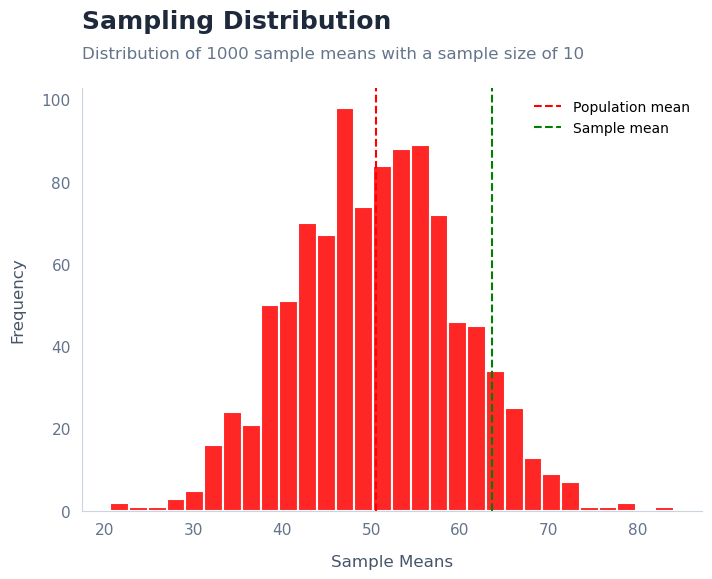

In [178]:
# Used custom styled_plot function
styled_plot(
    plot_type="hist",
    data=sample_means,
    title="Sampling Distribution",
    subtitle="Distribution of 1000 sample means with a sample size of 10",
    xlabel="Sample Means",
    ylabel="Frequency",
    color="red",
    show_mean=True,
    mean_label="Population mean",
    mean_color="red",
    secondary_mean=sample_mean,
    secmean_label="Sample mean",
    secmean_color="green"
)

plt.show()

Let's take a moment here to talk about what this graph shows. The mean of the first sample we took is indicated by the green line at 63.6.

But **we could have got any sample** right? We might have got a sample mean of 20 or 80 or, we might have been spot on the population mean... This is called a **sampling distribution**, and it represents the **possible outcomes** of taking one sample, we don't know which sample we have. 

But notice the **shape of this graph**. Despite our original data being totally spread out, our sample means follow a normal distribution, clustered around the sample mean indicated by the blue line. This is the **central limit theorem**, and this is the super power of statistics.

<h3>Central limit theorem</h3>

Central limit theorem says that the sampling distribution of the mean approaches a **normal distribution** as the sample size increases. As we have more data, the closer this graph will look to a normal distribution, the familiar bell curve, regardless of the shape of the population. 

Let's visualise this by graphing population distributions with different sample sizes:

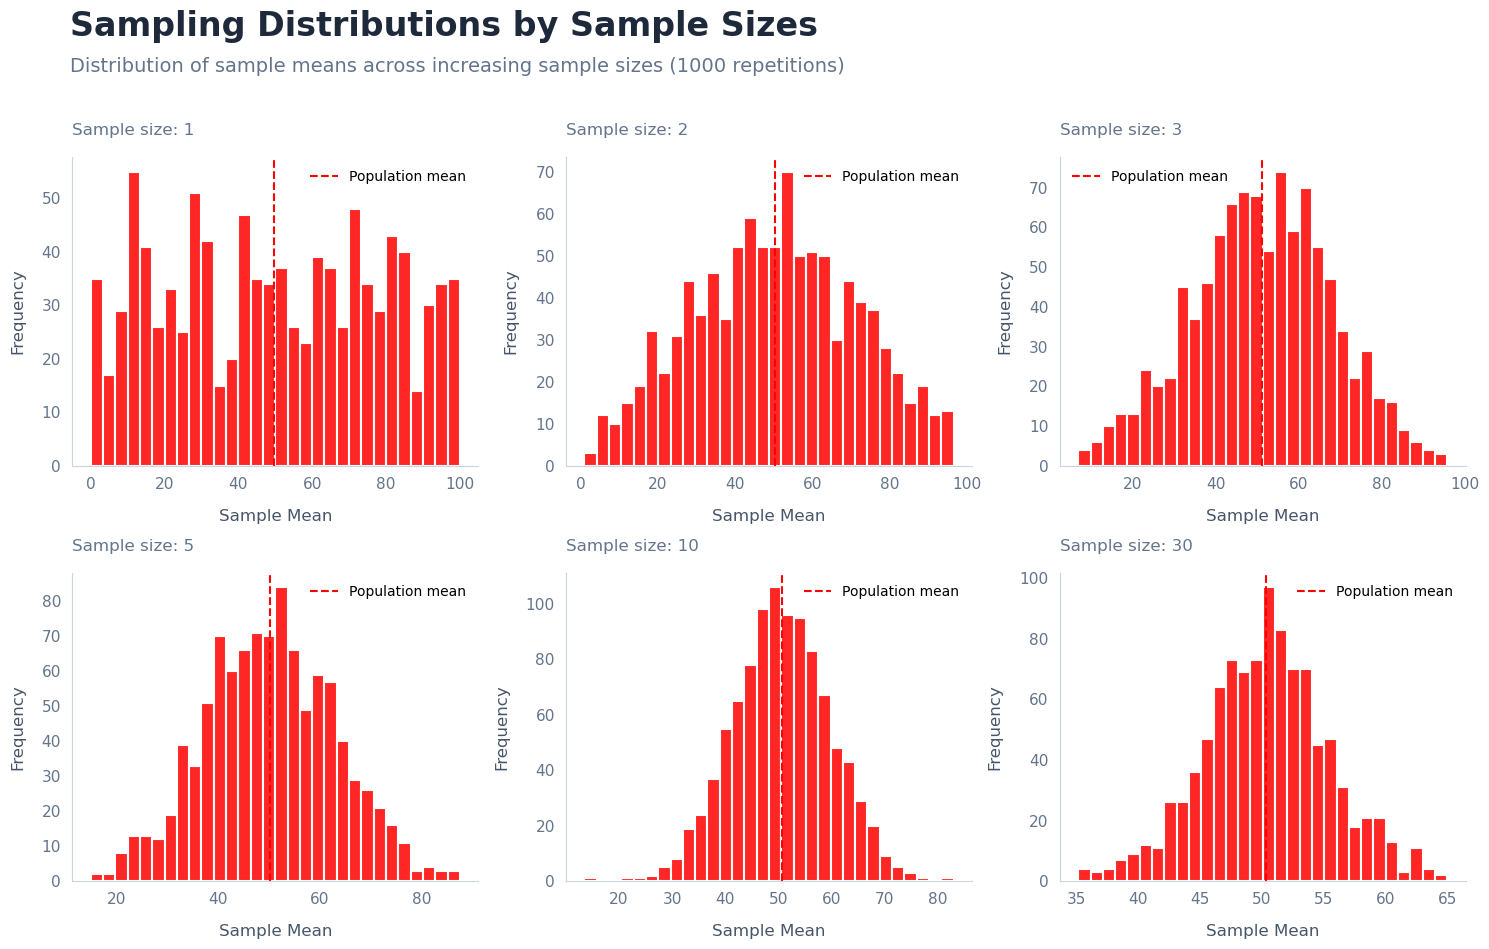

In [186]:
# Graph increasing sample sizes

# Instantiate numpy random number generator
# 42 is a seed we can reuse to get the same numbers again
rng = np.random.default_rng(42)

# Set 2 x 3 sub plots
fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9)
)

# Use same loop to get samples of different sizes

# Set a loop for 6 plots of different sample sizes
for ax, n in zip(axes.flat, [1, 2, 3, 5, 10, 30]):

    # Create blank list
    sample_means = []

    # Use same loop for a thousand repetitions
    for i in range(1000):
        sample = rng.choice(
            population,
            # Set sample size to n to pull from the values above
            size=n,
            replace=False
        )
        # Add means to list
        sample_means.append(sample.mean())

    # Turn list of means into an array
    sample_means = np.array(sample_means) 

    # Apply reusable plotting function
    styled_plot(
        data=sample_means,
        plot_type="hist",
        subtitle=f"Sample size: {n}",
        xlabel="Sample Mean",
        ylabel="Frequency",
        color="red",
        show_mean=True,
        mean_label="Population mean",
        mean_color="red",
        ax=ax
    )

# Main figure title
fig.text(
    0.05, 1.02,
    "Sampling Distributions by Sample Sizes",
    fontsize=24,
    fontweight="bold",
    color="#1e293b",
    ha="left"
)

# Main figure subtitle
fig.text(
    0.05, 0.98,
    "Distribution of sample means across increasing sample sizes (1000 repetitions)",
    fontsize=14,
    color="#64748b",
    ha="left"
)

# Adjust spacing
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

At first, if we are only able to get one data point it is random like our population data. But slowly as we collect more and **more data the bell curve appears**.

With a large enough sample size, **30 is generally considered reasonable**, we know our sample will be somewhere along a normal distribution. We don't know where we are, but we know we are in this shape. It is like being handed a map, we are not sure exactly where our sample is, but if we have enough data we know we will be somewhere along a bell curve. And this is the **core of inferential statistics**. 

It is this phenomena that allows us to apply powerful statistical techniques without needing to know what the population looks like. 

<h3>Standard error (SE)</h3>

So we know if we can get a sample of at least 30, we are somewhere along a normal distribution. But we still don't know exactly where, there is still a degree of uncertainty.

So **how can we quantify this uncertainty?**

The **standard error** is a measure of the variation caused by random samples. It helps us estimate from just one sample, what variation occurs when taking a sample from a population. To calculate the standard error of the mean we take into account the diminishing returns of increasing sample size by dividing the standard deviation by the square root of the sample size:

In [33]:
# Manual calculation of the standard error of the mean

# Instantiate numpy random number generator
# 42 is a seed we can reuse to get the same numbers again
rng = np.random.default_rng(42)

# Generate sample size of 30 from the population
sample = rng.choice(population, size=30, replace=False)

# Calculate the standard error of the mean using the formula
sample_size = len(sample)
sample_mean = sample.mean()
std = np.std(sample, ddof=1)
sem = std / np.sqrt(sample_size)

# Print sample statistics
print("Sample size:", sample_size)
print("Sample mean (point estimate):", round(sample_mean, 1))
print("Sample standard deviation:", round(std, 1), "\n")

print("Standard error of the mean:", round(sem, 1))

Sample size: 30
Sample mean (point estimate): 49.8
Sample standard deviation: 33.7 

Standard error of the mean: 6.2


From this formula we get a standard error of 6.2. What does this mean?

The **standard error is the start of taking into account the uncertainty** of sample variability. It is the standard deviation of this sample.

It is our first 'margin of error'. From just one sample, we are able to quantify uncertainty. It is a first step to building in uncertainty to our estimation and it can be used to build a confidence interval.

<h3>Confidence intervals</h3>

A confidence interval is a **range of values that describe the uncertainty surrounding an estimate** caused by sampling variability. Instead of just reporting the sammple mean, we can calculate a confidence interval by adding and minusing the standard error, or margin of error, from a point estimate to create lower and upper bounds.

Let's do just that, and construct our first confidence interval:

In [34]:
# Construct confidence interval

# Calculate standard error interval
lower_bound = sample_mean - sem
upper_bound = sample_mean + sem

# Print lower and upper bounds
print("Sample sem lower bound", round(lower_bound, 1))
print("Sample sem upper bound", round(upper_bound, 1), "\n")

# Print interval, population mean and comparison
print("Standard error interval:", round(lower_bound, 1), "to", round(upper_bound, 1))
print("Population mean:", round(population_mean, 1))
print("Standard error interval contains population mean?:", sample_mean - sem <= population.mean() <= sample_mean + sem)

Sample sem lower bound 43.6
Sample sem upper bound 56.0 

Standard error interval: 43.6 to 56.0
Population mean: 50.3
Standard error interval contains population mean?: True


We have a standard error interval of 43.6 to 56. Our population mean is 50.3, **inside this interval!** By taking a large enough sample and building in uncertainty of random sampling we have a prediction that captured the population mean are looking for.

This is a step up from our point estimate, which we know may have varied, and can now say we believe the population mean may fall within these bounds. But **how accurate is this interval** really? If we had a different sample would it have also included the population mean?

<h3>Confidence level</h3>

To test this, let's take a thousand samples, calculate the standard errors, intervals and see how many times we are correctly able to capture the population mean:

In [35]:
# Test accuracy of one standard error interval across 1000 samples

# Instantiate numpy random number generator
# 42 is a seed we can reuse to get the same numbers again
rng = np.random.default_rng(42)

# Create a table to be populated with information about samples
standard_error_accuracy = pd.DataFrame(columns=['sample_number', 'sample_mean', 'standard_error', 'lower_ci', 'upper_ci', 'contains_population_mean'])

# Generate a thousand random samples of size 30
for i in range(1000):
    sample = rng.choice(
        population,
        size=30,
        replace=False
    )

    # Calculate stample mean and standard error
    sample_mean = sample.mean()
    sample_sem = stats.sem(sample)

    # Calculate lower and upper confidence interval
    lower_ci = sample_mean - sample_sem
    upper_ci = sample_mean + sample_sem

    # add sample information to each table column
    standard_error_accuracy.loc[i] = [
        "Sample " + str(i + 1),
        # Add mean
        sample.mean(),
        # Add standard error of the mean
        sample_sem,
        # Add upper and lower bounds
        lower_ci,
        upper_ci,
        # Calculate interval
        lower_ci <= population.mean() <= upper_ci
    ]

# Display table with additional column
print(standard_error_accuracy['contains_population_mean'].value_counts(normalize=True).map('{:.1%}'.format))

contains_population_mean
True     71.2%
False    28.8%
Name: proportion, dtype: str


71.2% of the time we were able to correctly capture the population mean in this interval! Or in otherwords, if we pulled one sample, we could say we are 71% sure we have a sample where the population mean falls within a confidence interval one standard error. Pretty cool right? This is called a **confidence level**.

A confidence level describes the lik**elihood that a particular sampling method will produce a confidence interval that includes the population parameter**. Approximately 68.3% of samples will capture the population mean within one standard error.

Which is ok, no statistical test can predict an outcome with 100% certainty, but really **we want to be more accurate** than that. So what can we do? How could we extend this margin of error to have a higher degree of confidence?

<h3>Margin of error</h3>

The margin of error in the **maximum expected difference between the true population parameter and sample esitmate**. We can reverse our formula above by first deciding on the confidence interval we would like and using the margin of error formula. 

MOE = Critical Value * Standard Error

A **critical value is a multiplier** from a normal distribution that sets the width of a confidence interval's margin of error. It marks the number of standard errors away from a point estimate needed to reach a desired confidence level:

In [36]:
# Display confidence levels

# Data for common confidence levels
confidence_levels = {
    "Confidence Level": ["90%", "95%", "98%", "99%"],
    "Alpha": [0.10, 0.05, 0.02, 0.01],
    "Critical Value": [1.645, 1.960, 2.326, 2.576]
}

# Create DataFrame
confidence_levels = pd.DataFrame(confidence_levels)

# Display table
confidence_levels

,Confidence Level,Alpha,Critical Value
0,90%,0.10,1.645
1,95%,0.05,1.960
2,98%,0.02,2.326
3,99%,0.01,2.576


This table allows us to select a confidence level prior to an interval using the following steps:

1. Identify a sample statistic
2. Choose confidence level
3. Find the margin of error
4. Calculate the interval

Let's try this with a confidence level of 95%:

In [37]:
# 95% confidence level calculation

# Instantiate numpy random number generator
# 42 is a seed we can reuse to get the same numbers again
rng = np.random.default_rng(42)

# 1. Identify sample statistic

# Generate sample size of 30 from the population
sample = rng.choice(population, size=30, replace=False)
# Calculathe sample statistics, in this case the mean
sample_statistic = sample.mean()

# 2. Choose a confidence level in decimal format
confidence_level = 0.95

# 3. Find the standard error and margin of error
sample_sem = stats.sem(sample)
margin_of_error = 1.96 * sample_sem

# 4. Calculate the interval
lower_confidence_interval = sample_statistic - margin_of_error
upper_confidence_interval = sample_statistic + margin_of_error

# Print final results
print("Margin of error:", round(margin_of_error, 2))
print("95% confidence interval:", round(lower_confidence_interval, 2), "to", round(upper_confidence_interval, 2), "\n")

Margin of error: 12.07
95% confidence interval: 37.73 to 61.87 



To have a **confidence level of 95%** we multiplied our standard error by 1.96 as per the table to create a new confidence interval of 37.8 to 61.2. 

To proove this new interval, let's run a thousand samples and again using this multiplier each time we calculate a confidence interval and see how often we captured the population parameter now:

In [38]:
# Proof of 95% confidence interval across 1000 samples

# Instantiate numpy random number generator
# 42 is a seed we can reuse to get the same numbers again
rng = np.random.default_rng(42)

# Create a table to be populated with information about samples
standard_error_accuracy = pd.DataFrame(columns=['sample_number', 'sample_mean', 'standard_error', 'lower_ci', 'upper_ci', 'contains_population_mean'])

# Generate 1000 random samples of size 30
for i in range(1000):
    sample = rng.choice(
        population,
        size=30,
        replace=False
    )

    # Calculate stample mean and standard error
    sample_mean = sample.mean()
    sample_sem = stats.sem(sample)

    # Calculate lower and upper confidence interval
    lower_ci = sample_mean - (sample_sem * 1.96)
    upper_ci = sample_mean + (sample_sem * 1.96)

    # add sample information to each table column
    standard_error_accuracy.loc[i] = [
        "Sample " + str(i + 1),
        sample.mean(),
        sample_sem,
        lower_ci,
        upper_ci,
        lower_ci <= population.mean() <= upper_ci
    ]

# Print results
print(standard_error_accuracy['contains_population_mean'].value_counts(normalize=True).map('{:.1%}'.format))

contains_population_mean
True     94.3%
False     5.7%
Name: proportion, dtype: str


There we go! With our updated confidence interval based on our selected confidence level and margin of error formula we were able to **capture the population mean approx 95% of the time!**

By **extending our confidence interval using a margin of error we are to get more accurate predictions**. What if we wanted to have a smaller interval while staying at a desired confidence level?

<h3>Sample size</h3>

The only way to 'tighten' our confidence interval, staying at a desired confidence level, is to **increase our sample size**. 

As we saw with the central limit theorem, the more data we collected, the **sharper the bell curve appeared**. This theorem shows up in the standard error too as we increase the sample size.

In [91]:
# Sample sizes comparison table

# Instantiate numpy random number generator
# 42 is a seed we can reuse to get the same numbers again
rng = np.random.default_rng(42)

# Create a table with desired column headers
sample_sizes = pd.DataFrame(columns=['sample_size', 'sample_mean', 'standard_error', 'lower_ci', 'upper_ci'])

# Confidence level
confidence_level = 0.95

# Create a loop to find sample statistics based on different sample sizes
for i, n in zip(range(n), [10, 30, 50, 100, 250, 500]):
    sample = rng.choice(
        population,
        # n sample size to use the valuse set above in the loop
        size=n,
        replace=False
    )

    # Calculations for sample statistics
    sample_mean = sample.mean()
    sample_sem = stats.sem(sample)
    lower_ci = sample_mean - (sample_sem * 1.96)
    upper_ci = sample_mean + (sample_sem * 1.96)

    # Each time we use a sample size, add its statistics to the table
    sample_sizes.loc[i] = [
        len(sample),
        round(sample_mean, 2),
        round(sample_sem, 2),
        round(lower_ci, 2),
        round(upper_ci, 2)
    ]

# Display the table
sample_sizes

,sample_size,sample_mean,standard_error,lower_ci,upper_ci
0,10.0,63.60,9.10,45.76,81.44
1,30.0,47.17,4.99,37.38,56.95
2,50.0,49.76,4.42,41.09,58.43
3,100.0,52.70,2.88,47.05,58.35
4,250.0,49.15,1.86,45.51,52.79
5,500.0,50.15,1.28,47.64,52.67


As our sample **size increases, the standard error decreases and our confidence interval tightens**. Although this is not a linear relationship:

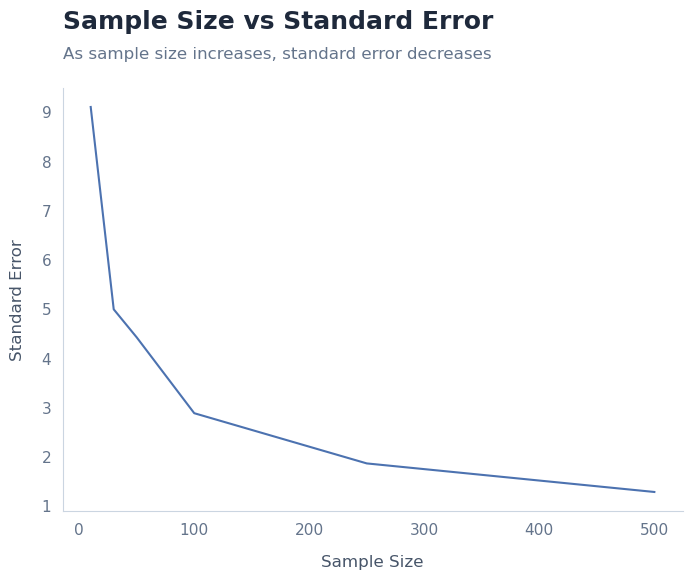

In [180]:
# Used custom styled_plot function
styled_plot(
    plot_type="line",
    data=sample_sizes,
    color="#4C72B0",
    x='sample_size',
    y='standard_error',
    title="Sample Size vs Standard Error",
    subtitle="As sample size increases, standard error decreases",
    xlabel="Sample Size",
    ylabel="Standard Error"
)

plt.show()

As we collect more data, our standard error decreases at an inverse square root rate.

For our **final estimation**, let's go with a sample size of 100:

In [41]:
# 95% confidence level calculation

# Instantiate numpy random number generator
# 42 is a seed we can reuse to get the same numbers again
rng = np.random.default_rng(42)

# 1. Identify sample statistic

# Generate sample size of 100 from the population
sample = rng.choice(population, size=100, replace=False)
sample_mean = sample.mean()

# 2. Choose a confidence level
confidence_level = 0.95

# 3. Find the margin of error
sample_sem = stats.sem(sample)
margin_of_error = 1.96 * sample_sem

# 4. Calculate interval
lower_confidence_interval = sample_statistic - margin_of_error
upper_confidence_interval = sample_statistic + margin_of_error

# Print final results
print("Point estimate:", round(sample_mean, 2))
print("Margin of error:", round(margin_of_error, 2))
print("95% confidence interval:", round(lower_confidence_interval, 2), "to", round(upper_confidence_interval, 2), "\n")

Point estimate: 48.43
Margin of error: 5.83
95% confidence interval: 43.97 to 55.63 



<h3>Interval estimates interpretation, applications and limitations</h3>

Here is our final interval estimate, we can express this as **"95% confident the population mean falls within 48.4 +/-5.8"** from a random sample size of 100. 

Data is difficult to collect, and sometimes impossible. Inferrential statistics shows, with some assumptions, useful conclusions can be draw from limit information. 

<h1>Probability</h1>

Instead of estimating the characteristics of a population, what if we did want to do our best to predict one data point?

Probability is the branch of mathematics that deals with measuring and quantifying how likely an event is to occur based on available data. Reasoning this uncertainty is a foundation part of data science and advanced statistical methods.

<h2>Objective probability</h2>

As opposed to subjective probability, using a personal feeling, experience or judgement to make a prediction, objective probability uses data.

<h3>Classical vs empirical</h3>

Classical probability is based on formal reasoning, by taking the number of desired outcomes by the total number of possible outcomes. 

Empirical probability is based on historical or experimental data to calculate more complex events. Represents the likelihood of an event occuring based on previous results of an experience or past events. Nmuber of times a specific event occures by the total number of events. Used to make accurate predictions based on sample data.

Random experiments are processes where the outcome cannot be predictiod with certainty. There is an unknown outcome

A) More than one possible outcome
B) Present each possible outcome in advance
C) The outcome of the experiment depends on chance

<h3>Bayes' thorem</h3>

Conditional probability, updating the probability of an event based on new information about the event. the likelihood multiplied by the prior all divded by the evidence. Transform a prior belief into a posterior probability using new data, the likelihood and evidence.

Used when there are two conditional probabilities, if you know one, you can know the other.

<h2>Probability distributions</h2>

Probability distributions describe the likelihood of the possible outcomes of a random event. Identifying the distribution of a dataset is a key step in any analysis for choosing statistical tests.

<h3>Discrete probability distributions</h3>

A countable number of possible values, often whole numbers. Distribution iis the exact probability of the possible value of the variable.

Probability mass functions represent discrete random variables. A function that provides probabilities for the possible outcomes of a random variable.

<h3>Continuous probability distributions</h3>

Measurable numbers that have an infinite number of possible values. We con only tell the probability within a range of values, bucketing the infinite values.

Probability density functions represent continous random variables.

<h3>Z-scores</h3>

Measure of how many standard deviations below or above the population mean a data point is. Used to better understand the relationship of data values.

Assuming a normal distribution z-score = ((data values - mean) / standard deviation)

Z-score zero: equal to the mean
Z-score positive: greater than the mean
Z-score negative: less than the mean